Bibliotecas

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ_PROJETO = Path("..").resolve()
if str(RAIZ_PROJETO / "src") not in sys.path:
    sys.path.append(str(RAIZ_PROJETO / "src"))

from perceptron_pp import Perceptron, metricas, visualizacao

Leitura dos dados

In [2]:
caminho_dados = RAIZ_PROJETO / "data" / "dataHoldout20262.txt"

if not caminho_dados.exists():
    raise FileNotFoundError(f"arquivo não encontrado em: {caminho_dados}")

dados = np.load(caminho_dados)

print("Formato: ", dados.shape)
print("Dimensões: ", dados.ndim)
print("Tipo: ", dados.dtype)

# Remodela para (m, 3): uma linha por exemplo, três colunas (x1, x2, yd)
dados = dados.reshape(-1, 3)

X = dados[:, :2]  # atributos x1, x2
y = dados[:, 2]   # tótulo yd (0 ou 1)

df = pd.DataFrame(dados, columns=["x1", "x2", "yd"])
print(f"Linhas: {df.shape[0]} | Colunas: {df.shape[1]}")
df.head()

Formato:  (1000, 3)
Dimensões:  2
Tipo:  float64
Linhas: 1000 | Colunas: 3


,x1,x2,yd
0,134.834443,0.901429,1.0
1,263.517819,0.197317,1.0
2,56.166711,-0.688011,0.0
3,20.910100,0.732352,1.0
4,216.401404,0.416145,1.0


Resumo estatístico e distribuição das classes

In [3]:
display(df.describe())
print(df["yd"].value_counts())

,x1,x2,yd
count,1000.000000,1000.000000,1000.000000
mean,176.017433,0.016673,0.508000
std,107.509789,0.570917,0.500186
min,1.778393,-0.993563,0.000000
25%,78.435132,-0.484202,0.000000
50%,178.837382,0.034981,1.000000
75%,270.244379,0.501128,1.000000
max,359.788941,0.999435,1.000000


yd
1.0    508
0.0    492
Name: count, dtype: int64


Gráfico do Problema não Linearmente Separável

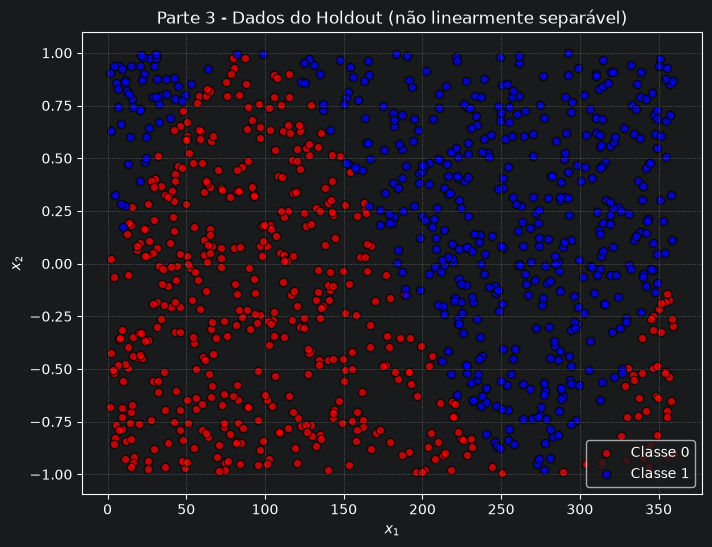

In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X[y == 0, 0], X[y == 0, 1], color="red",  label="Classe 0", alpha=0.7, edgecolors="k")
ax.scatter(X[y == 1, 0], X[y == 1, 1], color="blue", label="Classe 1", alpha=0.7, edgecolors="k")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title("Parte 3 - Dados do Holdout (não linearmente separável)")
ax.legend(loc="best")
ax.grid(True, linestyle=":", alpha=0.6)
plt.show()

Como apresentado no gráfico acima, não há uma reta que possa separar as duas classes presentes de forma dinstinta.

In [5]:
ID_EQUIPE = 1

rng = np.random.default_rng(ID_EQUIPE)
indices = rng.permutation(len(X))

n_treino = int(round(0.70 * len(X)))
idx_treino, idx_teste = indices[:n_treino], indices[n_treino:]

X_train, y_train = X[idx_treino], y[idx_treino]
X_test, y_test = X[idx_teste], y[idx_teste]

print(f"Treino: {len(X_train)} exemplos | Teste: {len(X_test)} exemplos")

Treino: 700 exemplos | Teste: 300 exemplos


In [6]:
# Normalização min-max: leva x1 e x2 para o intervalo [0, 1].
minimo = X_train.min(axis=0)
maximo = X_train.max(axis=0)

X_train_n = (X_train - minimo) / (maximo - minimo)
X_test_n = (X_test - minimo) / (maximo - minimo)

print("Treino normalizado: min", X_train_n.min(axis=0), "| max", X_train_n.max(axis=0))
print("Teste normalizado:  min", X_test_n.min(axis=0), "| max", X_test_n.max(axis=0))

Treino normalizado: min [0. 0.] | max [1. 1.]
Teste normalizado:  min [0.00145393 0.00599979] | max [0.99720768 0.99739772]


## Justificativa da normalização min-max (decisão de projeto)

Os atributos de `dataHoldout20262` estão em escalas muito distintas: x1 ∈ [1.8, 359.8] e
x2 ∈ [-1, 1]. Com pesos iniciais w ~ U(-0.5, +0.5), o termo w1·x1 dominaria u em ~2 ordens de
magnitude sobre w2·x2, deixando x2 praticamente sem influência na fronteira. A normalização
min-max para [0, 1] iguala as escalas mantendo o η = 0.1 indicado ("recomendações da literatura"),
e é ajustada **apenas com os dados de treino** (sem vazamento: o conjunto de teste apenas aplica
o mínimo/máximo aprendidos). As Partes I e II não normalizam porque o enunciado prescreve η e o
intervalo de pesos explicitamente para aqueles conjuntos, e neles a convergência ocorre mesmo
com a escala bruta.

In [7]:
modelo = Perceptron(eta=0.1, intervalo_pesos=(-0.5, 0.5), theta=0.0, rng=ID_EQUIPE)
modelo.fit(X_train_n, y_train, max_epocas=100, embaralhar=True, verbose=True)

print(f"Épocas executadas: {modelo.n_epocas_} | Ajustes: {modelo.n_ajustes_}")
print(f"Convergiu: {modelo.convergiu_}")
print(f"Pesos finais [w0, w1, w2]: {modelo.w_}")

Vetor inicial de pesos [w0, w1, w2]: [ 0.01182162  0.4504637  -0.35584039]
Épocas executadas: 100 | Ajustes: 15798
Convergiu: False
Pesos finais [w0, w1, w2]: [0.61182162 0.37419309 0.33905935]


Erros por Época

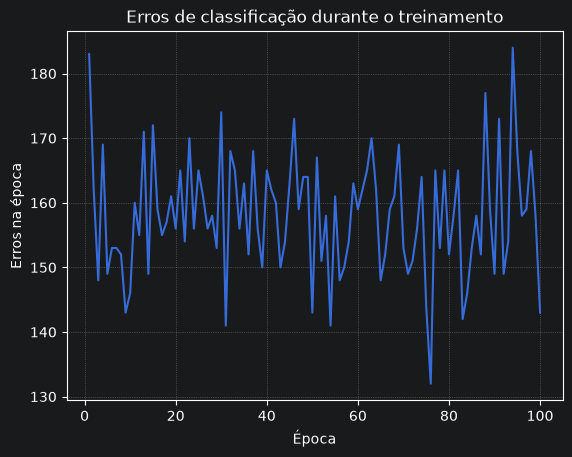

In [8]:
plt.plot(range(1, modelo.n_epocas_ + 1), modelo.erros_por_epoca_)
plt.xlabel("Época"); plt.ylabel("Erros na época")
plt.title("Erros de classificação durante o treinamento")
plt.grid(True, linestyle=":", alpha=0.6); plt.show()

In [9]:
y_pred_train = modelo.predict(X_train_n)
y_pred_test = modelo.predict(X_test_n)

print(metricas.tabela_metricas(metricas.avaliar(y_train, y_pred_train), titulo="Treinamento"))
print(metricas.tabela_metricas(metricas.avaliar(y_test, y_pred_test), titulo="Teste"))

+--------------------+
|    Treinamento     |
+-----------+--------+
|  Métrica  | Valor  |
+-----------+--------+
|  Acurácia | 0.5186 |
|  Precisão | 1.0000 |
| Revocação | 0.0792 |
|  F1-Score | 0.1468 |
+-----------+--------+
+--------------------+
|       Teste        |
+-----------+--------+
|  Métrica  | Valor  |
+-----------+--------+
|  Acurácia | 0.5633 |
|  Precisão | 1.0000 |
| Revocação | 0.0775 |
|  F1-Score | 0.1438 |
+-----------+--------+


Matriz de Confusão

Matriz de confusão (linhas = classe real, colunas = previsto):
 [[158   0]
 [131  11]]


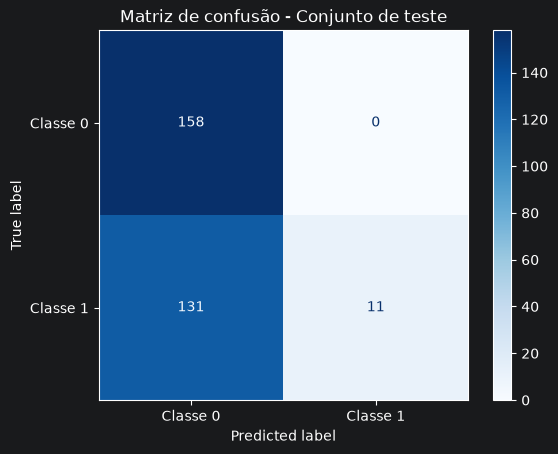

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay

matriz = metricas.matriz_confusao(y_test, y_pred_test)
print("Matriz de confusão (linhas = classe real, colunas = previsto):\n", matriz)
ConfusionMatrixDisplay(matriz, display_labels=["Classe 0", "Classe 1"]).plot(cmap="Blues")
plt.title("Matriz de confusão - Conjunto de teste")
plt.show()

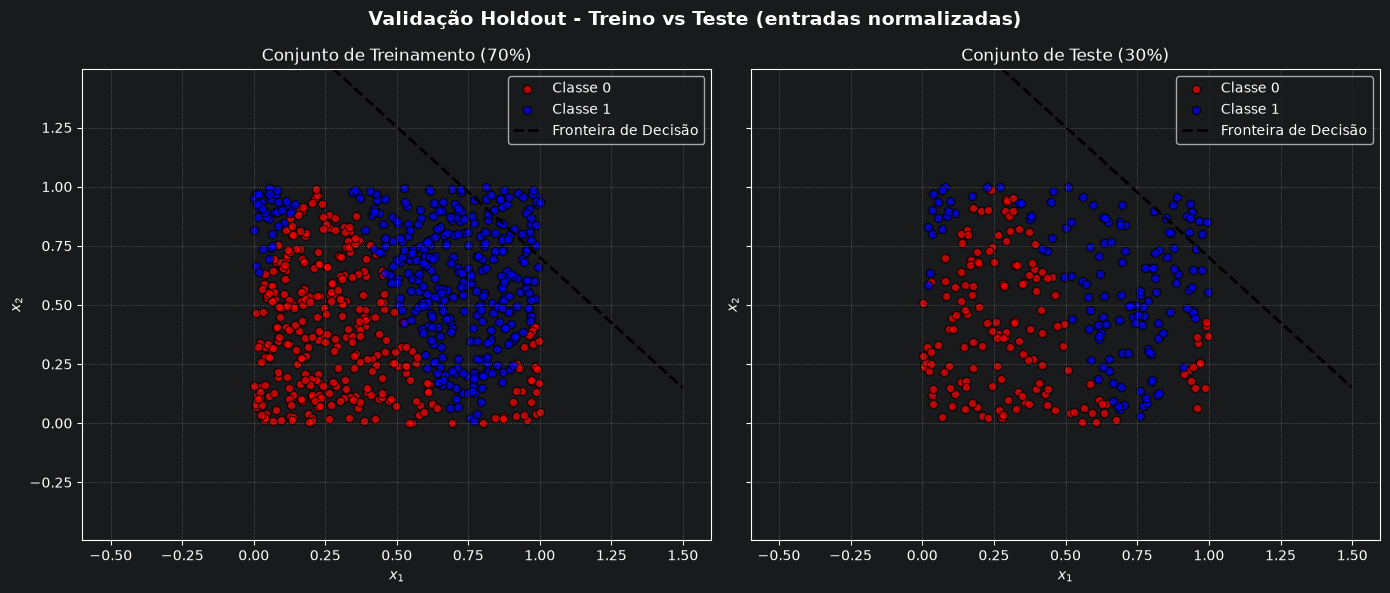

In [11]:
PASTA_RESULTADOS = RAIZ_PROJETO / "resultados"
PASTA_RESULTADOS.mkdir(exist_ok=True)

fig, axes = visualizacao.plot_comparacao_treino_teste(
    X_train_n, y_train, X_test_n, y_test, modelo,
    titulo="Validação Holdout - Treino vs Teste (entradas normalizadas)",
)
fig.savefig(PASTA_RESULTADOS / "parte3_treino_teste.png", dpi=150, bbox_inches="tight")
plt.show()

## Discussão da qualidade da solução (conjunto de teste)

A matriz de confusão e as métricas mostram um classificador que quase sempre prevê a classe 0:

- **Precisão = 1.0** (treino e teste): quando o neurônio prevê classe 1, acerta — mas são
  pouquíssimos casos;
- **Revocação ≈ 0.08**: cerca de 92% dos exemplos da classe 1 viram falsos negativos;
- **F1 ≈ 0.146 (treino) / 0.144 (teste)**: resume o desequilíbrio entre errar quase toda a
  classe 1 (revocação baixa) e nunca errar quando prevê classe 1 (precisão alta);
- **Acurácia = 0.519 (treino) / 0.563 (teste)**: mal supera o classificador trivial "tudo classe 0"
  (as classes estão quase 50/50: 508 vs 492 exemplos).

Esse é o comportamento esperado do Perceptron em um problema **não linearmente separável**: os
pesos oscilam a cada apresentação e o vetor final (~ [0.61, 0.37, 0.34], no espaço normalizado)
produz uma fronteira que prevê classe 1 somente em um canto extremo do espaço de entrada. Após
100 épocas (com apresentação aleatória dos exemplos a cada época, conforme o enunciado), o
resultado depende do último ajuste realizado, não de uma fronteira "ótima" — o limite aqui é
estrutural (função degrau + problema com sobreposição de classes), não de implementação: o mesmo
algoritmo convergiu em 5 épocas na Parte I, onde o problema é separável.

Melhorias possíveis, mas fora do escopo do enunciado: reter o vetor de pesos da época com menor
número de erros, ou a média dos pesos ao longo do tempo (pocket algorithm), ou um modelo com
fronteira não-linear.